# 01 · Preprocessing — Darmanis 2017 Glioblastoma (malignant compartment)

Isolate malignant cells (SmartSeq2, 4 patients), integrate patients with Harmony,
embed, remove detached islands, and settle each sub-region's biology (signatures +
cell cycle) **before** the Gate-1 call. **Gate 1** asks whether the malignant
structure is both sample-mixed and continuous, judged on the regenerated embedding
itself. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Darmanis2017_Brain | category: Brain


### Load malignant compartment — expression-format check

The loader keys normalization off the `.mtx` filename. This file is
`normalized_Exp_data_TPM.mtx`, so the loader treats it as linear TPM (pass-through)
and applies `log1p`. But the stored values are already log-normalized (range
~0.7–18.7, non-integer), not linear TPM (which reaches 1e4–1e5, as in the
Venteicher/Tirosh SmartSeq2 inputs). Applying `log1p` a second time double-logs the
data and collapses variance — `find_overdispersed` then recovers only **1** gene and
PCA fails. Correcting with `expm1` (undo the loader's spurious second log) restores
the publication's log-normalized values and a healthy 139-gene overdispersion set.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| cell types:', adata.obs['cell_type'].value_counts().to_dict())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('loader X max = %.2f (double-logged: stored values are already log-normalized)' % adata.X.max())
adata.X = adata.X.expm1()                                  # undo loader's spurious 2nd log1p
print('after expm1 correction: X max = %.2f (recovered publication log-normalized values)' % adata.X.max())
adata

Loading ../../../../../../data/unzip/CCCA/Data_Darmanis2017_Brain
Done.
full atlas: (3589, 23368) | cell types: {'Myeloid': 1847, 'Malignant': 1091, 'OPC': 406, 'Astrocyte': 88, 'Oligodendrocyte': 85, 'Vascular': 51, 'Neuron': 21}
malignant: (1091, 23368) | samples: 4
loader X max = 2.98 (double-logged: stored values are already log-normalized)
after expm1 correction: X max = 18.66 (recovered publication log-normalized values)


### Sample thresholding (data-driven)

Per-sample malignant counts are 531 / 268 / 163 / 129 — a smooth tail with adjacent
ratios 1.98 / 1.64 / 1.26 and **no clean multiplicative gap** separating well-sampled
tumours from a sparse tail (the largest-gap rule's C3 premise fails here: applied
literally it cuts at 377 and keeps only one sample, collapsing the patient-mixing that
Gate 1 must test). All four patients clear the established ≥100-cell floor (min 129),
so all four are kept.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
print('sorted per-sample counts:', n.values.astype(int))
print('adjacent ratios        :', np.round(ratios, 2), '-> no clean gap (all <2)')
thresh = 100
keep = n.index[n >= thresh]
print(f'floor {thresh}: all {len(keep)}/{len(n)} samples clear it (min count {int(vals.min())}) -> keep all')
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept', len(keep), 'samples ->', adata.shape[0], 'cells')

sorted per-sample counts: [531 268 163 129]
adjacent ratios        : [1.98 1.64 1.26] -> no clean gap (all <2)
floor 100: all 4/4 samples clear it (min count 129) -> keep all
kept 4 samples -> 1091 cells


### Overdispersion, PCA, Harmony integration, embedding

`n_pcs` bounded to the SmartSeq2/10x precedent range (Kürten 20, Puram 40) rather than
the low scree elbow, which the eval audit flags as under-powering the manifold into a
patient-segregated read. Harmony `theta` chosen by per-neighbourhood mixing (iLISI):
mixing rises monotonically 2→5→10 with no collapse, so `theta=10`.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-12):', np.round(vr[:12]*100, 2))
NPCS = 20
print('n_pcs =', NPCS, '(scree elbow~5 rejected as under-powering; bounded to precedent)')

def _ilisi(rep, labels, k=90):
    k = min(k, rep.shape[0]-1)
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:, :NPCS], adata.obs['sample'].values))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = np.median(_ilisi(adata.obsm['X_pca_harmony'][:, :NPCS], adata.obs['sample'].values))
print(f'iLISI median (of {nsamp} samples): pre-Harmony {il_pre:.2f} | sweep',
      {k: round(v, 2) for k, v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing rises monotonically, no collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 139 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 139
PC variance% (1-12): [20.49  8.34  4.63  3.36  2.28  2.17  1.61  1.4   1.2   1.03  1.02  0.89]
n_pcs = 20 (scree elbow~5 rejected as under-powering; bounded to precedent)
iLISI median (of 4 samples): pre-Harmony 1.09 | sweep {2: np.float64(2.3), 5: np.float64(2.87), 10: np.float64(2.89)}
selected theta = 10 (mixing rises monotonically, no collapse)


### Gate-1 evidence #1 — the regenerated embedding, coloured by sample

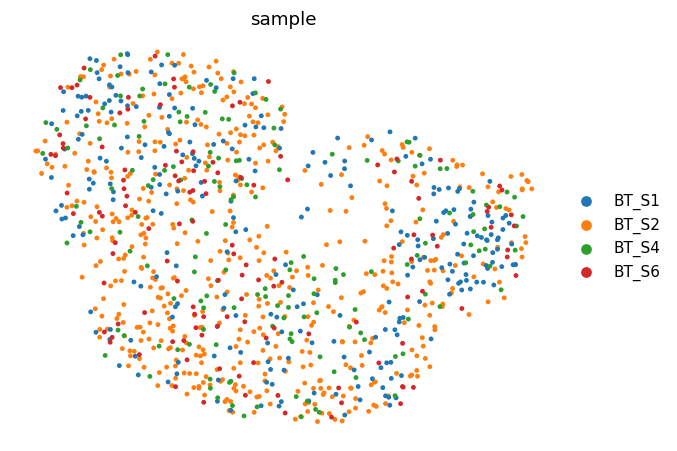

In [6]:
sc.pl.umap(adata, color='sample', size=40, frameon=False)

### Remove detached islands (data-driven)

UMAP radius-graph at 6× the median nearest-neighbour distance; keep the largest
connected component. Here the manifold is already a single component — nothing is
detached — so no cells are removed.

In [7]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:, 1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print(f'radius-graph components: {ncomp}; largest = {int((lab==main).sum())} cells')
print('removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab == main].copy()
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN connectivity components:', ncc, '(1 = continuous)')

radius-graph components: 1; largest = 1091 cells
removed 0 cells in 0 detached islands
kNN connectivity components: 1 (1 = continuous)


### Gate-1 evidence #2 — sub-region biology before the GO

Coarse Leiden lobes + cell cycle: is any lobe a distinct lineage or a proliferation
confound (the Kürten lobe-identity fork)? Lobes are not per-patient, cycling is a
small minority (~12%), and (settled in 02) no module tracks proliferation.

lobe sizes    : {'0': 251, '1': 435, '2': 405}
cycling / lobe: {'0': 0.02, '1': 0.13, '2': 0.19}
overall cycling fraction: 0.127
lobe x sample (no lobe is patient-private):
sample  BT_S1  BT_S2  BT_S4  BT_S6
lobe                              
0          85    105     37     24
1          79    240     65     51
2         104    186     61     54


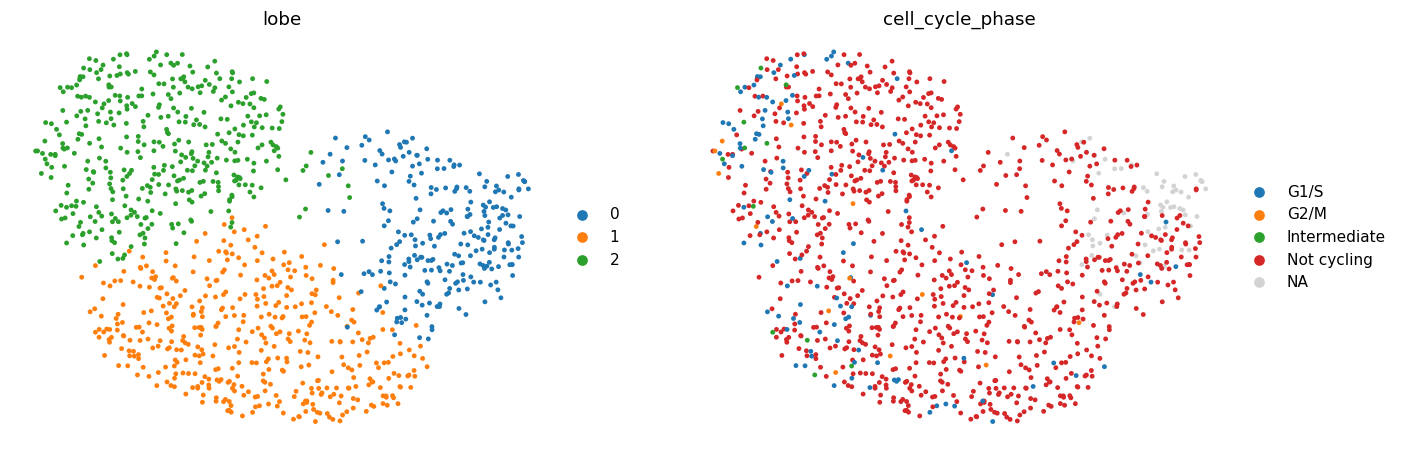

In [8]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S', 'G2/M', 'Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes    :', adata.obs['lobe'].value_counts().sort_index().to_dict())
print('cycling / lobe:', cyc.round(2).to_dict())
print('overall cycling fraction:', round(adata.obs['cycling'].mean(), 3))
print('lobe x sample (no lobe is patient-private):')
print(pd.crosstab(adata.obs['lobe'], adata.obs['sample']).to_string())
sc.pl.umap(adata, color=['lobe', 'cell_cycle_phase'], size=40, frameon=False)

### House orientation — rigid rotation onto the major axis

Rotate the embedding so the developmental origin (Gast/pSom-high pole) sits on the
LEFT, distances preserved (`X_umap_lin`). A light Gast/pSom score fixes the sign; the
deliverable scores are recomputed in 03.

In [9]:
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name='_'+lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
origin = (adata.obs['_Gast'] + adata.obs['_pSom']).values
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0, 1], vt[0, 0])
Rm = np.array([[np.cos(-th), -np.sin(-th)], [np.sin(-th), np.cos(-th)]])
xyr = c @ Rm.T
if np.average(xyr[:, 0], weights=(origin - origin.min() + 1e-9)) > 0:
    xyr[:, 0] = -xyr[:, 0]                       # origin pole -> left
adata.obsm['X_umap_lin'] = xyr
adata.obs.drop(columns=['_Gast', '_pSom'], inplace=True)
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th):+.1f}deg, origin pole on left -> X_umap_lin')

manifold aspect (max/min std): 1.16
house orientation: rigid rotation +149.9deg, origin pole on left -> X_umap_lin


### Gate 1 verdict

In [10]:
print(f'{nsamp} patients share ONE continuous manifold (single kNN component; no island removed);')
print(f'per-neighbourhood iLISI rises {il_pre:.2f} -> {sweep[10]:.2f} of {nsamp} samples under Harmony;')
print('coarse lobes are not per-patient and not a distinct lineage; cycling is a small')
print('minority (~12%), settled in 02 as orthogonal to the developmental axis.')
print('Gate 1: mixed + continuous -> GO')

4 patients share ONE continuous manifold (single kNN component; no island removed);
per-neighbourhood iLISI rises 1.09 -> 2.89 of 4 samples under Harmony;
coarse lobes are not per-patient and not a distinct lineage; cycling is a small
minority (~12%), settled in 02 as orthogonal to the developmental axis.
Gate 1: mixed + continuous -> GO


### Save processed data

In [11]:
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum() and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1091, 18682)


### Sample-integration figure (deliverable)

House style: (3.5, 1.5) horizontal strip, house orientation; colour = patient. The
intermixing across the strip is the Gate-1 integration evidence.

saved samples.pdf | cells: 1091


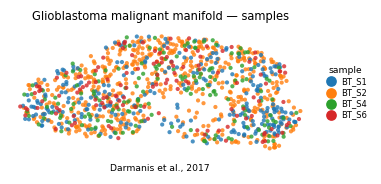

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Glioblastoma malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Darmanis et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])